# K-Means Clustering: segmentación de clientes por riesgo de abandono
**Proyecto 2 · Predicción de abandono de clientes de comercio electrónico · Equipo 5**

Objetivo: agrupar a los 50,000 clientes según su **comportamiento** en la plataforma y comprobar estadísticamente:
1. Cuántos clusters conviene usar (método del codo, silueta, Calinski-Harabasz y Davies-Bouldin).
2. Que los clusters son **estables** (no dependen del punto de inicio).
3. Que los clusters son **distintos entre sí** en sus variables (Kruskal-Wallis).
4. Que el **churn cambia** entre clusters (prueba ji cuadrada).

Estos son los mismos clusters que se muestran en el dashboard (pantalla 05 · Clientes prioritarios, pestaña Segmentos).

## Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## Importing the dataset

Se lee el CSV directo del repositorio del equipo. La base usa coma decimal ("27,4"), así que primero se convierte a número (igual que en `src/limpieza.py` del dashboard).

In [2]:
url = 'https://raw.githubusercontent.com/a01666361-beep/proyecto-churn/main/data/ecommerce_churn_final_comas.csv'
dataset = pd.read_csv(url, dtype=str)

# Convertir coma decimal a número
texto = ['Customer_ID','Gender','Country','City','Signup_Quarter']
for col in dataset.columns:
    if col not in texto:
        dataset[col] = pd.to_numeric(dataset[col].str.replace(',', '.', regex=False))

# La base guarda los días sin comprar en log(1 + x); se regresan a días
dataset['Dias_Sin_Comprar'] = np.expm1(dataset['Days_Since_Last_Purchase']).round().astype(int)

print(dataset.shape)
dataset.head()

(50000, 27)


,Customer_ID,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,...,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Signup_Quarter,Churned,Dias_Sin_Comprar
0,C00001,43,Male,France,Marseille,1.3610,14,27.4,6.0000,50.6,...,9.0,1.6094,16.3000,20.8,1,6.8610,2278.0,Q1,0,34
1,C00002,36,Male,UK,Manchester,0.9555,15,42.7,10.3000,37.7,...,7.0,1.3863,29.3645,23.3,3,6.9740,3028.0,Q4,0,71
2,C00003,45,Female,Canada,Vancouver,1.3610,10,24.8,1.6000,70.9,...,4.0,0.6931,29.3645,8.8,2,7.1630,2317.0,Q4,0,11
3,C00004,56,Female,USA,New York,1.2809,10,38.4,14.8000,41.7,...,2.0,1.7918,85.9000,31.0,3,7.7587,2674.0,Q1,0,47
4,C00005,35,Male,India,Delhi,1.4110,29,51.4,8.7378,19.1,...,1.0,2.4849,83.0000,50.4,4,8.0204,5354.0,Q4,0,73


### Variables para el clustering

Solo variables de **comportamiento** (sin edad, género ni país): queremos agrupar a los clientes por cómo usan la plataforma, no por quiénes son. La variable `Churned` **no** entra al clustering; se usa después para validar los grupos.

In [3]:
variables = ['Login_Frequency','Session_Duration_Avg','Pages_Per_Session','Cart_Abandonment_Rate',
             'Total_Purchases','Average_Order_Value','Dias_Sin_Comprar','Customer_Service_Calls',
             'Discount_Usage_Rate','Lifetime_Value','Email_Open_Rate','Mobile_App_Usage']

dataset[variables].describe().round(2)

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Total_Purchases,Average_Order_Value,Dias_Sin_Comprar,Customer_Service_Calls,Discount_Usage_Rate,Lifetime_Value,Email_Open_Rate,Mobile_App_Usage
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,11.62,27.66,8.74,57.04,2.53,4.73,29.27,5.68,41.71,7.08,20.94,19.37
std,7.81,10.49,3.66,16.21,0.49,0.38,28.87,2.67,20.20,0.66,13.89,8.94
min,0.00,1.00,1.00,0.00,0.00,3.31,0.00,0.00,0.24,0.00,0.00,0.00
25%,6.00,20.20,6.20,46.40,2.20,4.48,9.00,4.00,26.50,6.67,10.50,13.20
50%,11.00,27.66,8.70,58.10,2.56,4.74,21.00,5.00,41.71,7.13,20.80,19.37
75%,17.00,34.00,11.00,68.70,2.89,4.98,39.00,7.00,55.20,7.54,29.70,24.60
max,46.00,75.60,24.10,100.00,4.87,9.18,287.00,21.00,99.96,9.10,91.70,61.90


## Escalado de las variables

K-Means agrupa por **distancia euclidiana**. Sin escalar, una variable con valores grandes (ej. días sin comprar, hasta 300) pesaría mucho más que una con valores chicos (ej. llamadas a servicio, hasta 20). `StandardScaler` deja todas con media 0 y desviación estándar 1.

In [4]:
sc = StandardScaler()
X = sc.fit_transform(dataset[variables].values)

print("Media de cada variable escalada:", X.mean(axis=0).round(2))
print("Desviación estándar:", X.std(axis=0).round(2))

Media de cada variable escalada: [-0.  0.  0. -0.  0.  0.  0. -0.  0.  0.  0.  0.]
Desviación estándar: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Using the elbow method to find the optimal number of clusters

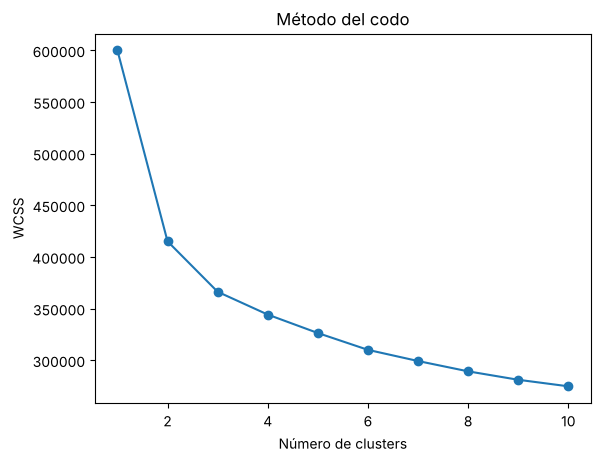

In [5]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', n_init = 10, random_state = 0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Método del codo')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.show()

In [6]:
# Cuánto baja el WCSS al agregar cada cluster (en %): el codo está donde la caída deja de ser grande
caida = pd.DataFrame({'Clusters (k)': range(1, 11), 'WCSS': np.round(wcss, 0)})
caida['Reducción vs k-1 (%)'] = (-caida['WCSS'].pct_change() * 100).round(1)
caida

,Clusters (k),WCSS,Reducción vs k-1 (%)
0,1,600000.0,NaN
1,2,415092.0,30.8
2,3,366248.0,11.8
3,4,344171.0,6.0
4,5,326317.0,5.2
5,6,310019.0,5.0
6,7,299205.0,3.5
7,8,289210.0,3.3
8,9,281056.0,2.8
9,10,274725.0,2.3


**Interpretación del codo:** la caída más fuerte del WCSS es al pasar de 1 a 2 clusters (−30.8%) y de 2 a 3 (−11.8%). A partir de ahí la mejora casi se estanca: de 3 a 4 baja solo 6.0% y después ~5% o menos. **El codo está en k = 3**: agregar un cuarto cluster casi no mejora la compactación de los grupos.

## Validación estadística del número de clusters

El método del codo es visual. Lo complementamos con tres índices:
- **Silueta** (−1 a 1, mayor es mejor): qué tan cerca está cada cliente de su cluster comparado con el cluster vecino.
- **Calinski-Harabasz** (mayor es mejor): separación entre clusters / dispersión dentro de ellos.
- **Davies-Bouldin** (menor es mejor): similitud promedio de cada cluster con el más parecido.

La silueta se calcula en una muestra de 8,000 clientes porque con 50,000 tarda mucho.

In [7]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

muestra = np.random.RandomState(0).choice(len(X), 8000, replace=False)
indices = []
for k in range(2, 11):
    km = KMeans(n_clusters = k, init = 'k-means++', n_init = 10, random_state = 0).fit(X)
    indices.append({'Clusters (k)': k,
                    'Silueta': silhouette_score(X[muestra], km.labels_[muestra]),
                    'Calinski-Harabasz': calinski_harabasz_score(X, km.labels_),
                    'Davies-Bouldin': davies_bouldin_score(X, km.labels_)})
indices = pd.DataFrame(indices).round(3)
indices

,Clusters (k),Silueta,Calinski-Harabasz,Davies-Bouldin
0,2,0.259,22272.330,1.416
1,3,0.165,15954.952,1.824
2,4,0.124,12387.689,2.081
3,5,0.126,10482.756,1.949
4,6,0.120,9352.555,1.921
5,7,0.114,8376.497,1.971
6,8,0.107,7674.652,1.974
7,9,0.100,7091.288,1.991
8,10,0.098,6576.484,2.020


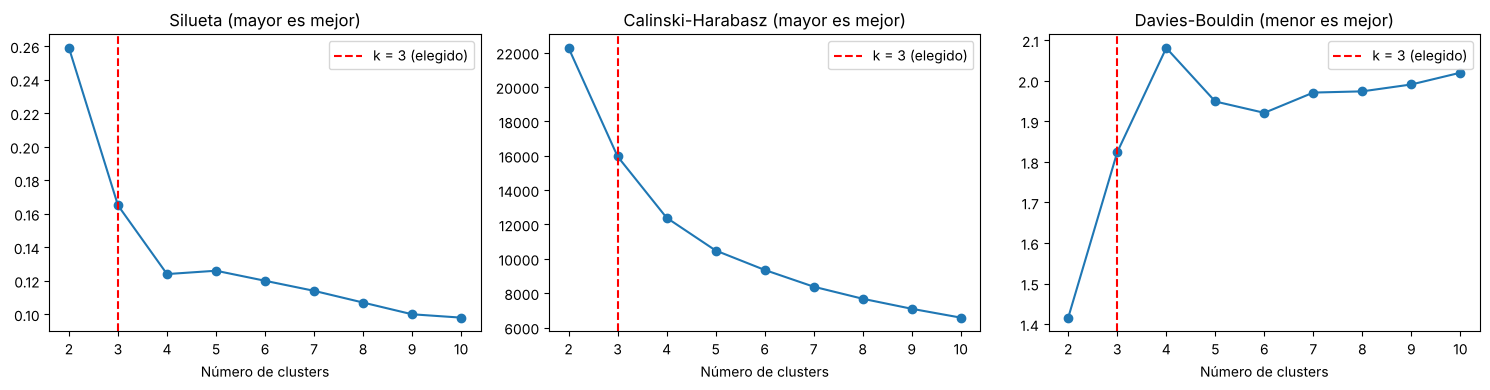

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, col, mejor in zip(ejes, ['Silueta','Calinski-Harabasz','Davies-Bouldin'], ['mayor','mayor','menor']):
    eje.plot(indices['Clusters (k)'], indices[col], marker='o')
    eje.axvline(3, color='red', linestyle='--', label='k = 3 (elegido)')
    eje.set_title(f'{col} ({mejor} es mejor)')
    eje.set_xlabel('Número de clusters')
    eje.legend()
plt.tight_layout()
plt.show()

**Interpretación de los índices:**

| k | Silueta | Calinski-Harabasz | Davies-Bouldin |
|---|---|---|---|
| 2 | **0.259** | **22,272** | **1.416** |
| **3** | **0.165** | **15,955** | **1.824** |
| 4 | 0.124 | 12,388 | 2.081 |
| 5 | 0.126 | 10,483 | 1.949 |

- Los tres índices son mejores con **k = 3 que con cualquier k mayor**: agregar un cuarto grupo empeora la separación (la silueta baja de 0.165 a 0.124).
- k = 2 tiene índices aún mejores, pero se descarta por el criterio de negocio (siguiente celda).
- Las siluetas son bajas en general: los clientes forman un **continuo** de más a menos activos y K-Means corta ese continuo en tramos.

### Criterio de negocio: ¿qué k separa mejor el churn?

Los índices anteriores solo miden la geometría de los grupos. Como el objetivo es **priorizar la retención**, también medimos qué tan relacionado está cada agrupamiento con el churn, con la **V de Cramér** (0 = sin relación, 1 = relación perfecta). `Churned` no se usa para formar los clusters, solo para evaluarlos.

In [9]:
from scipy import stats

asociacion = []
for k in range(2, 7):
    etiquetas = KMeans(n_clusters = k, init = 'k-means++', n_init = 10, random_state = 0).fit_predict(X)
    t = pd.crosstab(etiquetas, dataset['Churned'])
    chi2 = stats.chi2_contingency(t)[0]
    tasas = sorted((t[1] / t.sum(axis=1) * 100).round(1).tolist())
    asociacion.append({'Clusters (k)': k, 'V de Cramér': round(np.sqrt(chi2 / len(dataset)), 3),
                       'Churn de cada cluster (%)': tasas})
pd.DataFrame(asociacion)

,Clusters (k),V de Cramér,Churn de cada cluster (%)
0,2,0.151,"[20.6, 34.6]"
1,3,0.248,"[18.3, 22.3, 44.4]"
2,4,0.265,"[18.2, 18.4, 30.0, 48.3]"
3,5,0.261,"[17.7, 18.8, 27.0, 38.6, 48.2]"
4,6,0.331,"[9.5, 15.5, 26.1, 30.0, 40.7, 54.4]"


**Interpretación:**
- Con **k = 2** los clusters casi no separan el churn (20.6% contra 34.6%; V = 0.151).
- Con **k = 3** la relación con el churn sube a **V = 0.248** y el grupo de mayor riesgo queda bien separado (44.4% de churn).
- Con **k = 4** la V apenas sube (0.265), y lo que hace es partir a los clientes de bajo riesgo en **dos grupos con churn casi igual (18.2% y 18.4%)**. Esa diferencia es mínima: no justifica una campaña distinta para cada uno.

**Decisión: k = 3.** Es el codo del WCSS, tiene mejores índices que cualquier k mayor y separa claramente el riesgo de abandono sin crear grupos redundantes.

## Training the K-Means model on the dataset

In [10]:
kmeans = KMeans(n_clusters = 3, init = 'k-means++', n_init = 10, random_state = 0)
y_kmeans = kmeans.fit_predict(X)

pd.Series(y_kmeans).value_counts().sort_index()

0    16963
1    11475
2    21562
Name: count, dtype: int64

### Estabilidad de los clusters

K-Means empieza con centros al azar. Si los clusters fueran débiles, cambiarían mucho con otra semilla. Comparamos el resultado con 5 semillas distintas usando el **índice de Rand ajustado (ARI)**: 1 = mismos grupos, 0 = coincidencia al azar.

In [11]:
from sklearn.metrics import adjusted_rand_score

estabilidad = []
for semilla in [1, 7, 21, 42, 99]:
    otro = KMeans(n_clusters = 3, init = 'k-means++', n_init = 10, random_state = semilla).fit_predict(X)
    estabilidad.append({'Semilla': semilla, 'ARI vs modelo final': round(adjusted_rand_score(y_kmeans, otro), 3)})
pd.DataFrame(estabilidad)

,Semilla,ARI vs modelo final
0,1,0.994
1,7,0.996
2,21,0.980
3,42,0.996
4,99,0.983


## Perfil y nombre de cada cluster

In [12]:
dataset['Cluster'] = y_kmeans

perfil = dataset.groupby('Cluster')[variables + ['Churned']].mean().round(2)
perfil['Clientes'] = dataset['Cluster'].value_counts().sort_index()
perfil

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Total_Purchases,Average_Order_Value,Dias_Sin_Comprar,Customer_Service_Calls,Discount_Usage_Rate,Lifetime_Value,Email_Open_Rate,Mobile_App_Usage,Churned,Clientes
Cluster,,,,,,,,,,,,,,
0,5.28,18.81,5.65,70.35,2.05,4.66,28.96,7.15,41.33,6.47,10.72,12.07,0.44,16963
1,21.03,41.09,13.20,38.05,3.05,4.74,29.56,3.73,41.74,7.65,37.03,30.06,0.18,11475
2,11.61,27.48,8.80,56.68,2.64,4.77,29.34,5.57,42.00,7.25,20.41,19.43,0.22,21562


In [13]:
# Los nombres se asignan por actividad (promedio de inicios de sesión), de más a menos activo.
# Así no dependen del número que K-Means le pone a cada grupo.
nombres = ['Comprometidos', 'Regulares', 'Desconectados']
orden = perfil['Login_Frequency'].sort_values(ascending=False).index
mapa = {cluster: nombres[i] for i, cluster in enumerate(orden)}

dataset['Segmento'] = dataset['Cluster'].map(mapa)
perfil.index = perfil.index.map(mapa)
perfil = perfil.loc[nombres]

resumen = pd.DataFrame({
    'Clientes': perfil['Clientes'],
    'Churn (%)': (dataset.groupby('Segmento')['Churned'].mean() * 100).round(1),
    'Inicios de sesión': perfil['Login_Frequency'],
    'Apertura de correos (%)': perfil['Email_Open_Rate'],
    'Uso de la app': perfil['Mobile_App_Usage'],
    'Carrito abandonado (%)': perfil['Cart_Abandonment_Rate'],
    'Llamadas a servicio': perfil['Customer_Service_Calls'],
    'Días sin comprar': perfil['Dias_Sin_Comprar'],
}).loc[nombres]
resumen

,Clientes,Churn (%),Inicios de sesión,Apertura de correos (%),Uso de la app,Carrito abandonado (%),Llamadas a servicio,Días sin comprar
Comprometidos,11475,18.3,21.03,37.03,30.06,38.05,3.73,29.56
Regulares,21562,22.3,11.61,20.41,19.43,56.68,5.57,29.34
Desconectados,16963,44.4,5.28,10.72,12.07,70.35,7.15,28.96


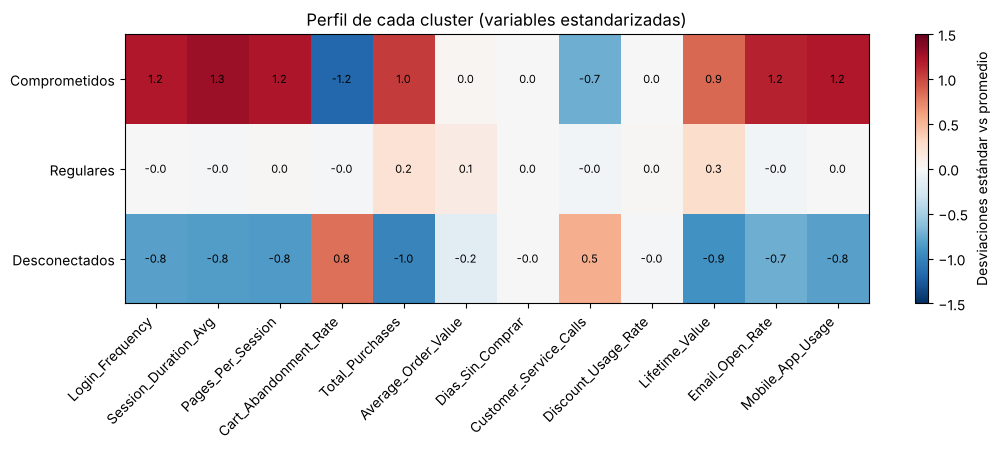

In [14]:
# Mapa de calor del perfil: cada celda es el promedio estandarizado (0 = promedio de la base)
perfil_z = pd.DataFrame(X, columns=variables).groupby(dataset['Segmento']).mean().loc[nombres]

plt.figure(figsize=(12, 3.5))
plt.imshow(perfil_z.values, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
plt.colorbar(label='Desviaciones estándar vs promedio')
plt.xticks(range(len(variables)), variables, rotation=45, ha='right')
plt.yticks(range(len(nombres)), nombres)
for i in range(len(nombres)):
    for j in range(len(variables)):
        plt.text(j, i, f'{perfil_z.values[i, j]:.1f}', ha='center', va='center', fontsize=8)
plt.title('Perfil de cada cluster (variables estandarizadas)')
plt.show()

## Visualising the clusters

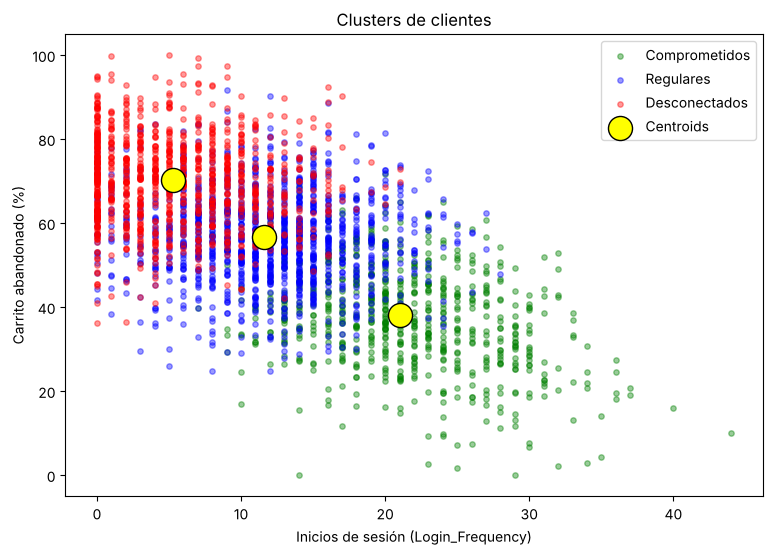

In [15]:
# Igual que en clase: dos variables en los ejes y los centroides en amarillo.
# Se usa una muestra de 3,000 clientes para que se vean los puntos.
i_x, i_y = variables.index('Login_Frequency'), variables.index('Cart_Abandonment_Rate')
Xo = dataset[variables].values                 # valores originales (sin escalar) para los ejes
centros = sc.inverse_transform(kmeans.cluster_centers_)
m = muestra[:3000]
colores = {'Comprometidos': 'green', 'Regulares': 'blue', 'Desconectados': 'red'}
inverso = {v: k for k, v in mapa.items()}

plt.figure(figsize=(9, 6))
for nombre in nombres:
    c = inverso[nombre]
    sel = m[y_kmeans[m] == c]
    plt.scatter(Xo[sel, i_x], Xo[sel, i_y], s = 15, c = colores[nombre], alpha = 0.4, label = nombre)
plt.scatter(centros[:, i_x], centros[:, i_y], s = 300, c = 'yellow', edgecolor='black', label = 'Centroids')
plt.title('Clusters de clientes')
plt.xlabel('Inicios de sesión (Login_Frequency)')
plt.ylabel('Carrito abandonado (%)')
plt.legend()
plt.show()

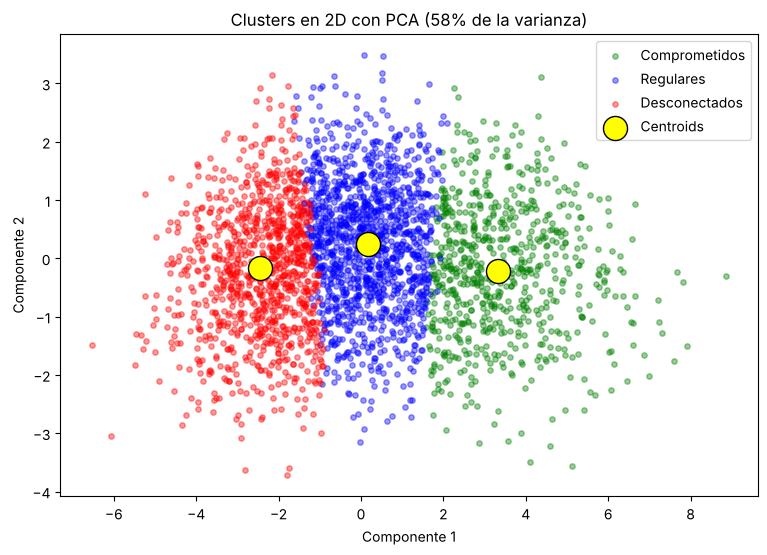

In [16]:
# Vista con las 12 variables: PCA proyecta a 2 dimensiones
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)
centros_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
for nombre in nombres:
    c = inverso[nombre]
    sel = m[y_kmeans[m] == c]
    plt.scatter(X_pca[sel, 0], X_pca[sel, 1], s = 15, c = colores[nombre], alpha = 0.4, label = nombre)
plt.scatter(centros_pca[:, 0], centros_pca[:, 1], s = 300, c = 'yellow', edgecolor='black', label = 'Centroids')
plt.title(f'Clusters en 2D con PCA ({pca.explained_variance_ratio_.sum():.0%} de la varianza)')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend()
plt.show()

## Pruebas estadísticas: ¿los clusters son realmente distintos?

### 1. ¿Las variables cambian entre clusters? (Kruskal-Wallis)

Se usa Kruskal-Wallis (versión no paramétrica del ANOVA) porque las variables no tienen distribución normal.
- H0: la variable tiene la misma distribución en los 3 clusters.
- H1: al menos un cluster es distinto.

Con 50,000 clientes casi cualquier diferencia sale significativa, así que también se reporta el **tamaño del efecto (épsilon²)**: < 0.01 despreciable, 0.01 a 0.08 pequeño, 0.08 a 0.26 moderado, > 0.26 grande.

In [17]:
n = len(dataset)
pruebas = []
for var in variables:
    grupos = [dataset.loc[dataset['Segmento'] == s, var] for s in nombres]
    H, p = stats.kruskal(*grupos)
    epsilon2 = H / (n - 1)
    pruebas.append({'Variable': var, 'H': round(H, 1), 'p-value': p, 'Épsilon²': round(epsilon2, 3)})

pruebas = pd.DataFrame(pruebas).sort_values('Épsilon²', ascending=False)
pruebas['Efecto'] = pd.cut(pruebas['Épsilon²'], [-1, 0.01, 0.08, 0.26, 1],
                           labels=['Despreciable', 'Pequeño', 'Moderado', 'Grande'])
pruebas['p-value'] = pruebas['p-value'].map(lambda v: f'{v:.2e}')
pruebas

,Variable,H,p-value,Épsilon²,Efecto
4,Total_Purchases,33164.0,0.00e+00,0.663,Grande
1,Session_Duration_Avg,30718.9,0.00e+00,0.614,Grande
2,Pages_Per_Session,29166.9,0.00e+00,0.583,Grande
11,Mobile_App_Usage,27541.4,0.00e+00,0.551,Grande
0,Login_Frequency,27462.2,0.00e+00,0.549,Grande
3,Cart_Abandonment_Rate,27355.7,0.00e+00,0.547,Grande
9,Lifetime_Value,25435.1,0.00e+00,0.509,Grande
10,Email_Open_Rate,23769.2,0.00e+00,0.475,Grande
7,Customer_Service_Calls,11506.9,0.00e+00,0.230,Moderado
5,Average_Order_Value,859.8,1.99e-187,0.017,Pequeño


### 2. ¿El churn cambia entre clusters? (prueba ji cuadrada)

`Churned` no se usó para formar los clusters. Si el churn es distinto entre ellos, los clusters sirven para priorizar la retención.
- H0: el churn es independiente del cluster.
- H1: el churn depende del cluster.

In [18]:
tabla = pd.crosstab(dataset['Segmento'], dataset['Churned']).loc[nombres]
tabla.columns = ['Se queda (0)', 'Abandona (1)']
chi2, p, gl, esperados = stats.chi2_contingency(tabla)
v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

tabla['Churn (%)'] = (tabla['Abandona (1)'] / tabla.sum(axis=1) * 100).round(1)
print(f"Ji cuadrada = {chi2:,.1f} | gl = {gl} | p-value = {p:.2e} | V de Cramér = {v_cramer:.3f}")
tabla

Ji cuadrada = 3,071.1 | gl = 2 | p-value = 0.00e+00 | V de Cramér = 0.248


,Se queda (0),Abandona (1),Churn (%)
Segmento,,,
Comprometidos,9370,2105,18.3
Regulares,16754,4808,22.3
Desconectados,9426,7537,44.4


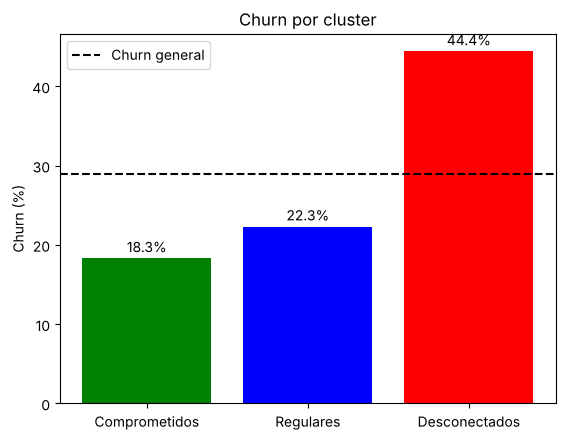

In [19]:
plt.bar(tabla.index, tabla['Churn (%)'], color=[colores[s] for s in tabla.index])
plt.axhline(dataset['Churned'].mean() * 100, color='black', linestyle='--', label='Churn general')
for i, v in enumerate(tabla['Churn (%)']):
    plt.text(i, v + 0.8, f'{v}%', ha='center')
plt.title('Churn por cluster')
plt.ylabel('Churn (%)')
plt.legend()
plt.show()

## Comparación con cluster jerárquico

Como en clase, se construye el dendrograma con el método de Ward. Con 50,000 clientes el dendrograma no se puede leer, así que se usa una muestra de 2,000. Después se compara si el cluster jerárquico con 3 grupos coincide con K-Means.

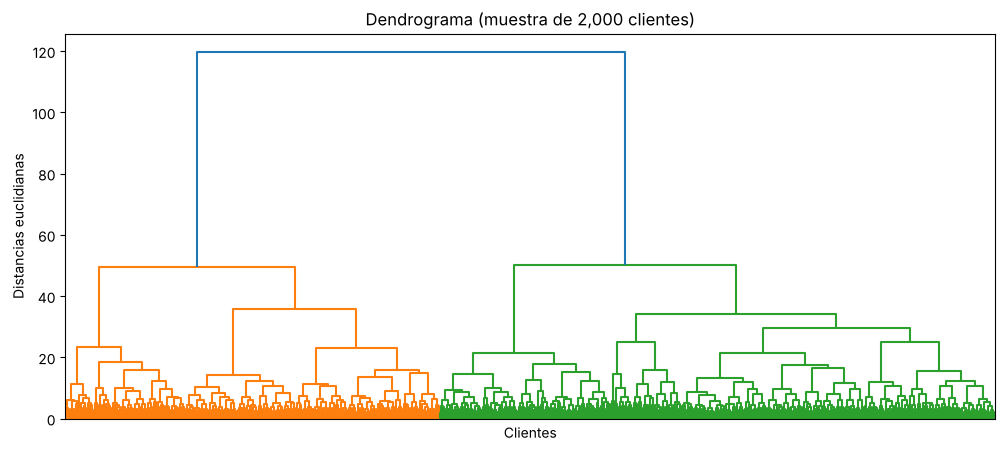

In [20]:
import scipy.cluster.hierarchy as sch

m2 = muestra[:2000]
plt.figure(figsize=(12, 5))
dendrograma = sch.dendrogram(sch.linkage(X[m2], method = "ward"), no_labels=True)
plt.title("Dendrograma (muestra de 2,000 clientes)")
plt.xlabel("Clientes")
plt.ylabel("Distancias euclidianas")
plt.show()

In [21]:
from sklearn.cluster import AgglomerativeClustering

cj = AgglomerativeClustering(n_clusters = 3, linkage = "ward")
y_cj = cj.fit_predict(X[m2])

print("Coincidencia jerárquico vs K-Means (ARI):", round(adjusted_rand_score(y_kmeans[m2], y_cj), 3))
pd.crosstab(pd.Series(dataset['Segmento'].values[m2], name='K-Means'), pd.Series(y_cj, name='Jerárquico'))

Coincidencia jerárquico vs K-Means (ARI): 0.334


Jerárquico,0,1,2
K-Means,,,
Comprometidos,467,6,0
Desconectados,0,304,365
Regulares,339,515,4


## Conclusiones

**Número de clusters**
- El método del codo marca **k = 3**: después de 3, cada cluster extra reduce el WCSS en 6% o menos.
- La silueta, Calinski-Harabasz y Davies-Bouldin son mejores con k = 3 que con cualquier k mayor.
- Con k = 4, dos clusters quedaban con un churn casi idéntico (18.2% y 18.4%), así que la diferencia entre ellos no aportaba a la retención.

**Validez estadística**
- **Estables:** con 5 semillas distintas los clusters coinciden en ARI de 0.980 a 0.996. Prácticamente no dependen del punto de inicio (más estables que con k = 4).
- **Distintos entre sí:** Kruskal-Wallis es significativo (p < 0.05) en 11 de las 12 variables. El efecto es **grande** en 8 (compras, duración de sesión, páginas, uso de la app, inicios de sesión, carrito abandonado, Lifetime_Value y apertura de correos) y **moderado** en llamadas a servicio. Los días sin comprar (p = 0.887) y el uso de descuentos **no** distinguen a los clusters.
- **Relacionados con el churn:** ji cuadrada = 3,071.1, p < 0.001, V de Cramér = 0.248 (relación moderada). El churn va de 18.3% a 44.4% según el cluster.

**Perfiles**

| Cluster | Clientes | Churn | Perfil |
|---|---|---|---|
| Comprometidos | 11,475 | 18.3% | Más inicios de sesión (21), sesiones largas, abren correos (37%), usan la app, poco carrito abandonado (38%) y pocas llamadas |
| Regulares | 21,562 | 22.3% | Actividad media en todo: 12 inicios de sesión, 20% de apertura de correos, 57% de carrito abandonado |
| Desconectados | 16,963 | 44.4% | Casi no entran (5 inicios de sesión), apenas abren correos (11%), abandonan 70% de sus carritos y son los que más llaman a servicio (7) |

**Limitaciones**
- La silueta es baja (0.165): los clusters son tramos de un continuo de actividad, no grupos naturalmente separados. Sirven para comunicar y priorizar, no como "tipos" de cliente.
- El cluster jerárquico con 3 grupos coincide solo moderadamente con K-Means (ARI = 0.334 en la muestra): la frontera entre grupos no es nítida.
- Los días sin comprar y el uso de descuentos no aportan a la segmentación; se podrían quitar en una siguiente versión.

**Uso en el dashboard:** estos 3 clusters se muestran en la pantalla 05 · Clientes prioritarios (pestaña Segmentos), cruzados con la probabilidad de abandono del modelo de regresión logística.